# Assignment 2

**Statement of AI use**: AI was used to get feedback on answers of this assignment's tasks. It was also used to find out how to print the imaginary part of the signals in task 1b. It was also used to generate code for computing the array of $c_n$ values in task 1c. It was also used to move down the phase graph in the figure produced in task 1c. It was also used to find out how to set tick positions of the y axis of the phase graph of task 1c. Lastly, it was used to find and fix bugs.

## Task 1

### a)

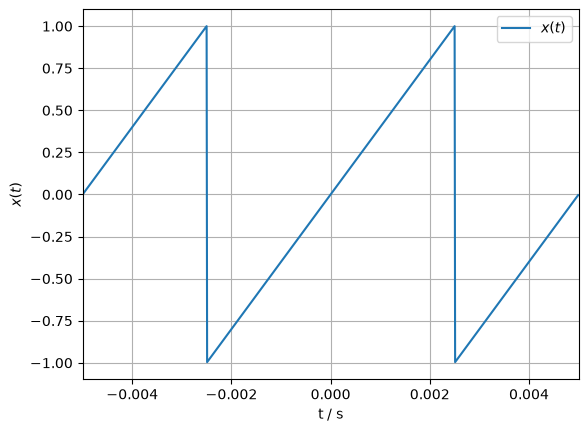

In [96]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import sounddevice as sd

t = np.arange(-5 * 10 ** -3, 5 * 10 ** -3, 0.01 * 10 ** -3)

x = -1 + (1 / 0.0025) * np.mod(t - 0.0025, 0.005)

fig, ax = plt.subplots()
ax.grid()

ax.set_xlim(-5 * 10 ** -3, 5 * 10 ** -3)

ax.set_xlabel('t / s')
ax.set_ylabel('$x(t)$')

ax.plot(t, x, label="$x(t)$")
ax.legend()

### b) 

The definition of exponential continuous-time Fourier series says that any $T_0$-periodic continuous-time signal $x(t)$ can be expressed in terms of its exponential continuous-time Fourier series:

$$
x(t) = \sum_{n=-\infty}^{\infty} c_ne^{jn\omega_0t}
$$

The signal $x(t) = -1 + \frac{1}{0.0025}\text{mod}(t - 0.0025, 0.005)$ is a $T_0$-periodic continuous-time signal. We can therefore approximate it as described above.

However, in a program we cannot have an infinite terms. Therefore we have to approximate the signal with a limited amount of terms. The figure generated by the code below shows that as $N$ grows larger, or approaches infinity, the approximated signals $x_N(t)$ approaches the real signal $x(t)$.

Additionally, the program's approximations of the signals' plots (the real part of the signals) with different values of N are accurate since the imaginary part of the signals are close to zero.

N=1: max |Im| = 0.00e+00
N=2: max |Im| = 2.78e-17
N=10: max |Im| = 2.08e-16
N=100: max |Im| = 2.98e-16


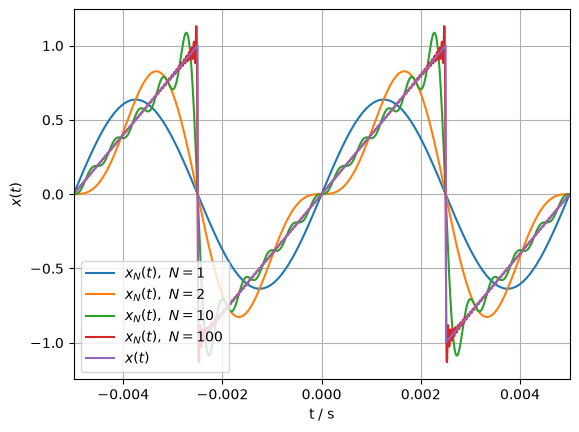

In [108]:
Ns = [1, 2, 10, 100]

T_0 = 5 * 10 ** -3
w_0 = 2 * np.pi / T_0

fig, ax = plt.subplots()
ax.grid()

ax.set_xlim(-5 * 10 ** -3, 5 * 10 ** -3)

ax.set_xlabel('t / s')
ax.set_ylabel('$x(t)$')

for N in Ns:
    x_N = 0
    for k in range(-N, N + 1):
        c_n = 0 if k == 0 else ((-1) ** k) * (1j) * (1 / (k * np.pi))
        term = c_n * np.exp(1j * k * w_0 * t)
        x_N += term

    print(f"N={N}: max |Im| = {np.max(np.abs(np.imag(x_N))):.2e}") # AI Generated
    x_N = np.real(x_N)
    ax.plot(t, x_N, label=f"$x_N(t), \\ N = {N}$")

ax.plot(t, x, label="$x(t)$")

ax.legend()

    

### c)

The signal $x(t)$ is $T_0$-periodic, where $T_0 = 5 \, \text{ms}$, which gives that $\omega_0 = \frac{2 \pi}{T_0} = \frac{2 \pi}{5 \cdot 10^{-3}} \approx 1257 \, \text{rad/s}$. A transform table therefore shows that the corresponding Fourier transform function is as follows:

$$
X(\omega) = 2 \pi \sum_{n}c_n \delta(\omega - n \omega_0) \iff X(\omega) = 2 \pi \sum_{n}c_n \delta(\omega - 1257 n)
$$

From the graphs in the figure generated by the code below we can see that low frequencies dominate the signal, since the components $c_{-1}$ and $c_1$ have the highest magnitudes. The signal's features will therefore mostly be determined by $c_{-1}$ and $c_1$, the remaining components will "fine-tune" the approximation to the real signal. The result in task 1b shows the approximation of the signal with different amounts of components. The first approximation with $N=1$ shows what the approximated signal looks like when it's only determined by $c_{-1}$ and $c_1$. As $N$ grows larger, we see that the approximated signals don't deviate from the general shape of the approximation $x_N(t)$ when $N=1$.

<StemContainer object of 3 artists>

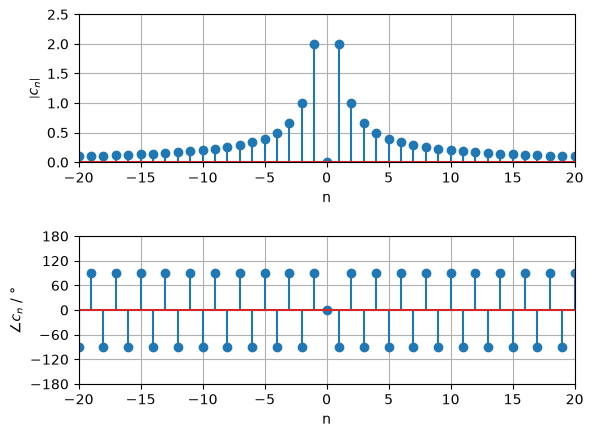

In [98]:
T_0 = 5 * 10 ** -3
w_0 = 2 * np.pi / T_0

M = 100

k = np.arange(-M, M + 1, 1)
wn = k * w_0

# AI generated
c_n = np.zeros(len(k), dtype=complex) 
nz = k != 0
c_n[nz] = ((-1.0) ** k[nz]) * (1j) * (1 / (k[nz] * np.pi))
# AI generated stops here

Xn = 2 * np.pi * c_n

fig, ax = plt.subplots(2, 1)
ax[0].grid()
ax[1].grid()
fig.subplots_adjust(hspace=0.5) # AI used here

ax[0].set_xlim(-20, 20)
ax[0].set_xlabel('n')
ax[0].set_ylim(0, 2.5)
ax[0].set_ylabel('$\\left| c_n \\right|$')

ax[1].set_xlim(-20, 20)
ax[1].set_xlabel('n')
ax[1].set_ylim(-180, 180)
ax[1].set_yticks(np.arange(-180, 181, 60)) # AI used here
ax[1].set_ylabel('$\\angle c_n$ / °')

ax[0].stem(k, np.abs(Xn))
ax[1].stem(k, 180 / np.pi * np.angle(Xn))

## Task 2

Using a transform table pair for real poles with $n = 2$, $t e^{-\alpha t} u(t) \iff \frac{1}{(\alpha + j\omega)^2}$, the frequency response of the system becomes:

$$
h(t) = \alpha^2 t e^{-\alpha t} u(t) \iff H(\omega) = \frac{\alpha^2}{(\alpha + j\omega)^2}
$$

For low frequencies, the system barely affects the magnitude of the input signal $x(t)$, since the highest value of $\left|H(\omega)\right|$ is 1, but for higher frequencies the magnitude is reduced. The frequency response function therefore describes that the system is a low-pass filter. Additionally, the system barely affects the phase of input signals with low frequencies, but for signals with high frequencies the change of the phase approaches around $160^\circ$.

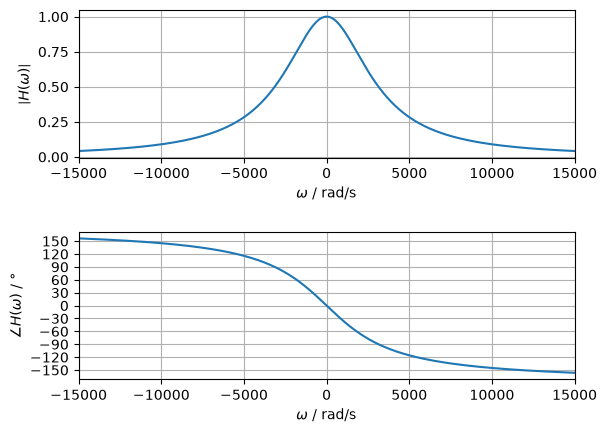

In [99]:
dw = 10
w = np.arange(-15e3, 15e3, dw)

alpha = 1000 * np.pi
H = alpha ** 2 / ((alpha + 1j * w) ** 2)

fig, ax = plt.subplots(2, 1)
ax[0].grid()
ax[1].grid()
fig.subplots_adjust(hspace=0.5)

ax[0].set_xlim(-15e3, 15e3)
ax[0].set_xlabel('$\\omega$ / rad/s')
ax[0].set_ylabel('$\\left| H(\\omega) \\right|$')

ax[1].set_xlim(-15e3, 15e3)
ax[1].set_xlabel('$\\omega$ / rad/s')
ax[1].set_yticks(np.arange(-180, 181, 30))
ax[1].set_ylabel('$\\angle H(\\omega)$ / °')

ax[0].plot(w, np.abs(H))
ax[1].plot(w, 180 / np.pi * np.angle(H))

## Task 3

### a)

For low frequencies, the magnitude of the output signal $Y(\omega)$ is about 1.75, but for high frequencies, the magnitude approaches zero. 

When comparing the spectrum of the input signal $X(\omega)$ with the spectrum of the output signal $Y(\omega)$, we see that the magnitude of low frequencies is smaller in $Y(\omega)$, compared to $X(\omega)$. We also see that the magnitude converges to zero quicker in the spectrum of the output signal, compared to the spectrum of the input signal.

<StemContainer object of 3 artists>

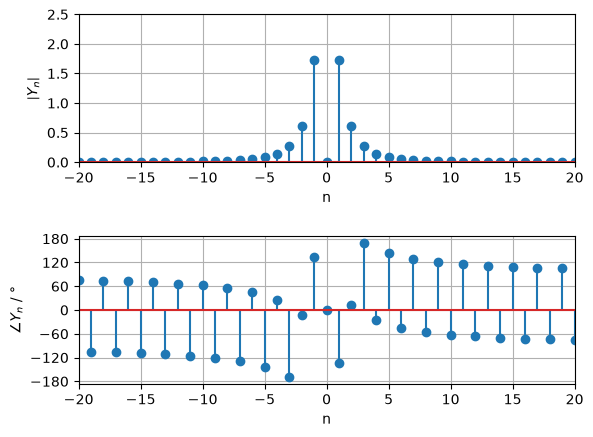

In [100]:
Hn = alpha ** 2 / ((alpha + 1j * wn) ** 2)

Yn = Hn * Xn

fig, ax = plt.subplots(2, 1)
ax[0].grid()
ax[1].grid()
fig.subplots_adjust(hspace=0.5)

ax[0].set_xlim(-20, 20)
ax[0].set_ylim(0, 2.5)
ax[0].set_xlabel('n')
ax[0].set_ylabel('$\\left| Y_n \\right|$')

ax[1].set_xlim(-20, 20)
ax[1].set_xlabel('n')
ax[1].set_yticks(np.arange(-180, 181, 60))
ax[1].set_ylabel('$\\angle Y_n$ / °')

ax[0].stem(k, np.abs(Yn))
ax[1].stem(k, 180 / np.pi * np.angle(Yn))

### b)

To begin with, the imaginary part of the signals with the different values of N are close to zero, so the real part of the signals are accurate.

We see in task 1b that the more components (with higher frequencies) we add, the more similiar the signal becomes compared to the real signal. This is especially true in the areas where the signal very sharply declines and increases. So the components with the higher frequencies determine the signal's appearance in these areas the most. The system, which is a low-pass filter, will therefore affect these areas the most. This is visible in the result below, as in the areas where the input signal previously sharply declined and increased, the output signal has a more "smooth" look. The components $c_{-1}$ and $c_1$ have also been reduced, which is apparent as the output signals have the minimum and maximum values of around -0.75 and 0.75 respectively, compared to the input signals which have the respective values of around -1 and 1.

N=1: max |Im| = 0.00e+00
N=2: max |Im| = 3.53e-17
N=10: max |Im| = 5.55e-17
N=100: max |Im| = 6.65e-17


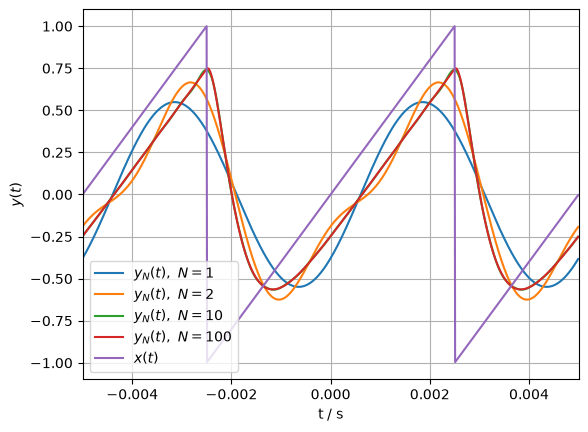

In [105]:
fig, ax = plt.subplots()
ax.grid()

ax.set_xlim(-5 * 10 ** -3, 5 * 10 ** -3)

ax.set_xlabel('t / s')
ax.set_ylabel('$y(t)$')

for N in Ns:
    y_N = 0
    for k in range(-N, N + 1):
        y_N += Yn[k + M] * np.exp(1j * k * w_0 * t)
    y_N = y_N / (2 * np.pi)
    print(f"N={N}: max |Im| = {np.max(np.abs(np.imag(y_N))):.2e}")
    y_N = np.real(y_N)
    ax.plot(t, y_N, label=f"$y_N(t), \\ N = {N}$")

ax.plot(t, x, label=f"$x(t)$")

ax.legend()